In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pypfopt import EfficientFrontier, risk_models, expected_returns, plotting

# Load data
df = pd.read_csv('/Users/macbook/Downloads/indonesia-financial-timeseries/data/clean_data.csv', parse_dates=['Date'], index_col='Date')

# Kita gunakan 4 aset utama (abaikan USDIDR karena itu nilai tukar, bukan aset investasi langsung)
assets = ['IHSG', 'GOLD', 'OIL', 'SP500']
df_assets = df[assets].dropna()

# Hitung return harian
returns = df_assets.pct_change().dropna()

# Hitung Expected Returns (rata-rata return tahunan) dan Covariance Matrix (risiko)
mu = expected_returns.mean_historical_return(df_assets)
S = risk_models.sample_cov(df_assets)

print("Expected Returns Tahunan:")
print(mu.round(4))

Expected Returns Tahunan:
IHSG     0.0524
GOLD     0.0864
OIL      0.0041
SP500    0.1186
dtype: float64


In [2]:
# Buat model Efficient Frontier (Max Sharpe Ratio)
ef = EfficientFrontier(mu, S)

# Cari bobot optimal
weights = ef.max_sharpe()
cleaned_weights = ef.clean_weights()

print("Alokasi Portofolio Optimal (Max Sharpe Ratio):")
for asset, weight in cleaned_weights.items():
    print(f"{asset:8s}: {weight*100:.2f}%")

# Tampilkan performa portofolio
performance = ef.portfolio_performance(verbose=True)

Alokasi Portofolio Optimal (Max Sharpe Ratio):
IHSG    : 14.49%
GOLD    : 36.52%
OIL     : 0.00%
SP500   : 48.99%
Expected annual return: 9.7%
Annual volatility: 11.2%
Sharpe Ratio: 0.87


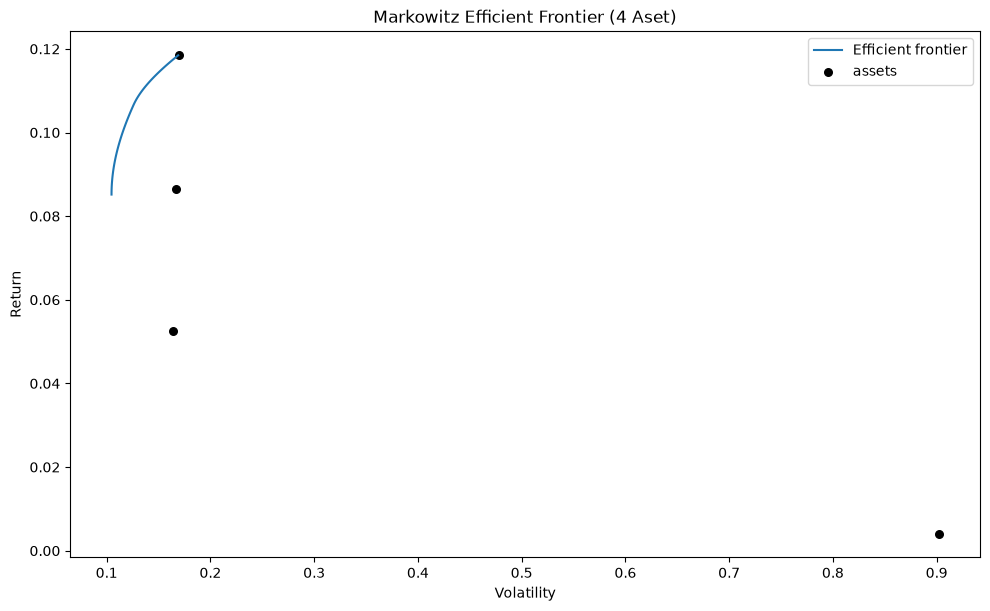

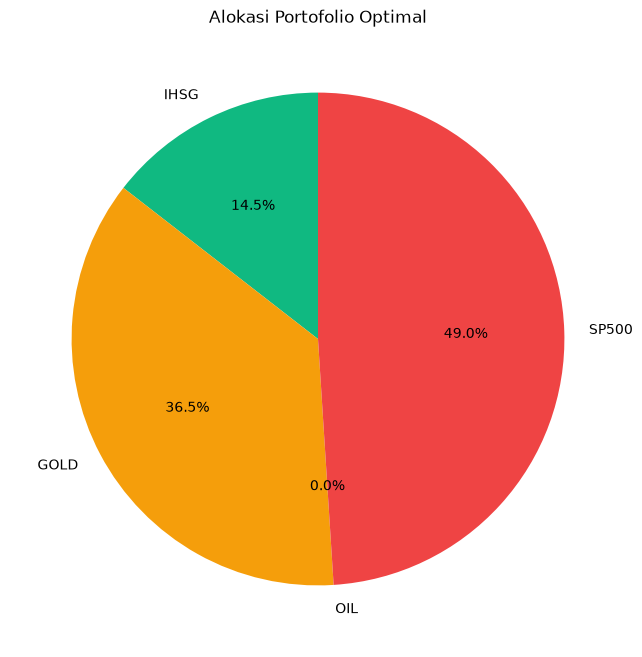

In [6]:
# 1. Buat objek BARU khusus untuk plotting (jangan pakai ef yang sudah di-solve)
ef_plot = EfficientFrontier(mu, S)

fig, ax = plt.subplots(figsize=(10, 6))
plotting.plot_efficient_frontier(ef_plot, ax=ax, show_assets=True)
plt.title('Markowitz Efficient Frontier (4 Aset)')
plt.show()

# 2. Plot Alokasi Aset (Pie Chart)
# (Kode ini tetap sama seperti sebelumnya)
labels = list(cleaned_weights.keys())
sizes = list(cleaned_weights.values())

plt.figure(figsize=(8, 8))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, colors=['#10b981', '#f59e0b', '#3b82f6', '#ef4444'])
plt.title('Alokasi Portofolio Optimal')
plt.show()

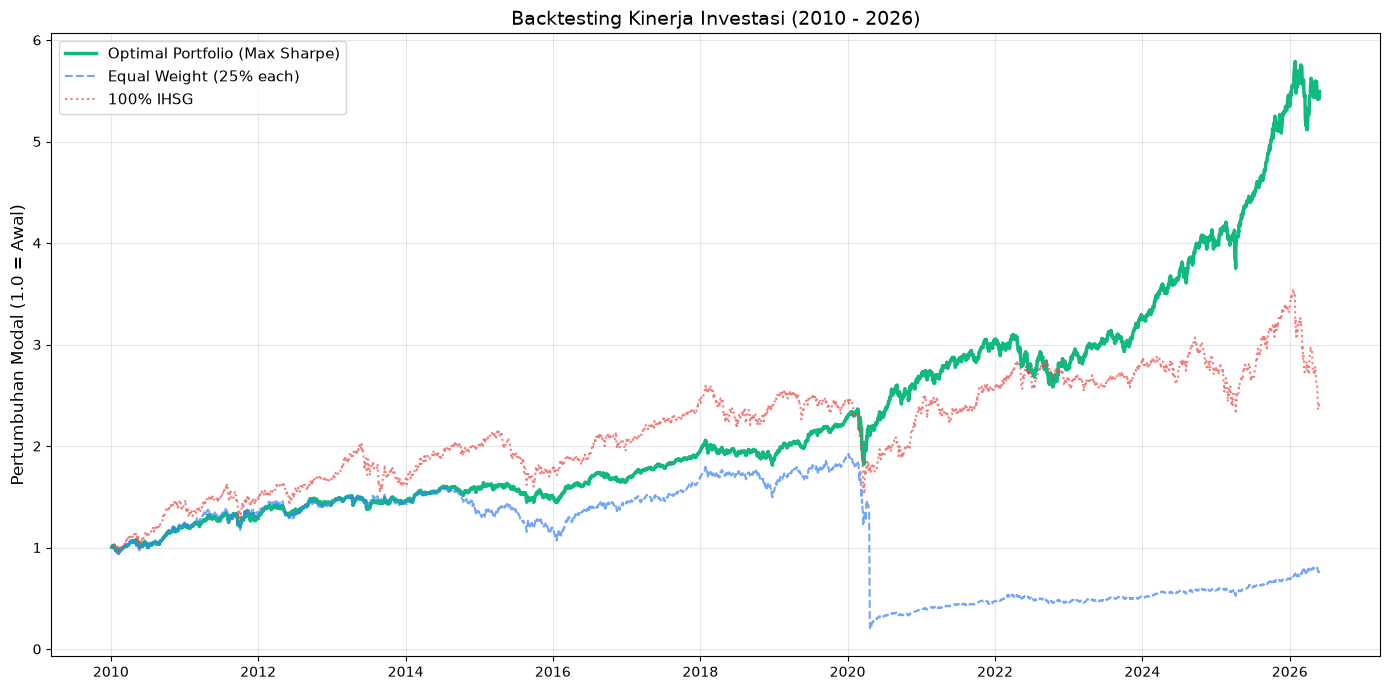

Total Growth 100% IHSG          : 137.93%
Total Growth Equal Weight       : -24.99%
Total Growth Optimal Portfolio  : 449.13%


In [7]:
# 1. Hitung return harian dari portofolio optimal kita
# Kita mengalikan return masing-masing aset dengan bobot optimalnya
optimal_weights = np.array([cleaned_weights[asset] for asset in assets])
portfolio_returns = returns.dot(optimal_weights)

# 2. Sebagai pembanding, kita buat portofolio "Naive" (Bagi rata 25% ke 4 aset)
equal_weights = np.array([0.25, 0.25, 0.25, 0.25])
equal_portfolio_returns = returns.dot(equal_weights)

# 3. Hitung akumulasi pertumbuhan modal (Cumulative Returns)
cum_optimal = (1 + portfolio_returns).cumprod()
cum_equal = (1 + equal_portfolio_returns).cumprod()
cum_ihsg = (1 + returns['IHSG']).cumprod()

# 4. Visualisasi Perbandingan
plt.figure(figsize=(14, 7))
plt.plot(cum_optimal.index, cum_optimal, label='Optimal Portfolio (Max Sharpe)', color='#10b981', linewidth=2.5)
plt.plot(cum_equal.index, cum_equal, label='Equal Weight (25% each)', color='#3b82f6', linestyle='--', alpha=0.7)
plt.plot(cum_ihsg.index, cum_ihsg, label='100% IHSG', color='#ef4444', linestyle=':', alpha=0.7)

plt.title('Backtesting Kinerja Investasi (2010 - 2026)', fontsize=14)
plt.ylabel('Pertumbuhan Modal (1.0 = Awal)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Tampilkan total pertumbuhan akhir
print(f"Total Growth 100% IHSG          : {(cum_ihsg.iloc[-1] - 1) * 100:.2f}%")
print(f"Total Growth Equal Weight       : {(cum_equal.iloc[-1] - 1) * 100:.2f}%")
print(f"Total Growth Optimal Portfolio  : {(cum_optimal.iloc[-1] - 1) * 100:.2f}%")